# Exploratory Data Analysis

**Purpose:** Explore booking trends, service demand, staff performance, revenue, and retention.


## 1. Load and Validate

In [83]:
# Import necessary libraries
import sys
sys.path.append("..")
 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from src.validate import validate

sns.set_theme(style="whitegrid")   
FIG = Path(".../reports/figures"); 
FIG.mkdir(parents=True, exist_ok=True)

In [84]:
# Load and revalidate data
df = pd.read_parquet("../data/processed/booking_clean.parquet")
df = validate(df)

All checks passed: 49,462 rows, 20 columns


In [85]:
# Overview
print("Rows:", f"{len(df)}", "Columns:", f"{df.shape[1]}")
print("Date range:", df["start"].min().date(), "to", df["start"].max().date())
print("Unique customers:", df["id"].nunique())
print("Number of appointments:", df["number"].nunique()) 
print()
print(df["status"].value_counts(normalize=True).round(3))
print(df["source"].value_counts(normalize=True).round(3))
print(df["service_type"].value_counts(normalize=True).round(3))

Rows: 49462 Columns: 20
Date range: 2024-08-09 to 2026-10-31
Unique customers: 5219
Number of appointments: 38926

status
Completed    0.900
Cancel       0.092
No-show      0.007
Name: proportion, dtype: float64
source
2025.csv    0.439
2026.csv    0.426
2024.csv    0.135
Name: proportion, dtype: float64
service_type
Natural Nails        0.439
Nails Enhancement    0.437
Add-ons              0.049
Bare Necessities     0.039
Waxing Services      0.025
Kids Services        0.012
Name: proportion, dtype: float64


## 2. Booking Growth and Trends Analysis

### a) Number of booking overall , by month, day in a week and hour in a day

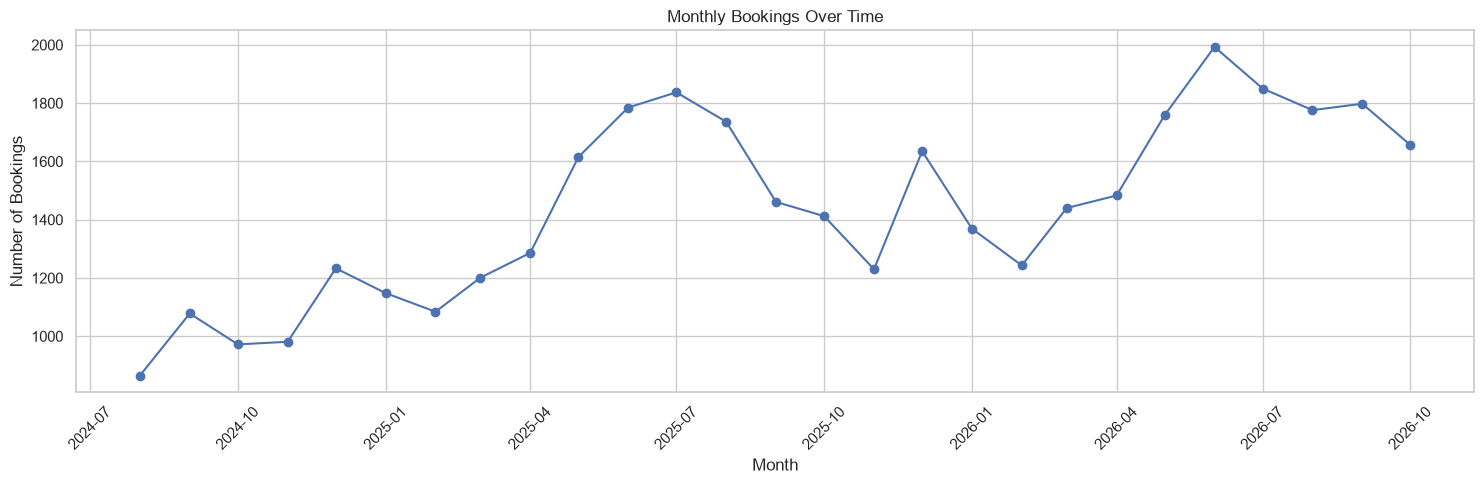

In [88]:
booking_time = (
    df.groupby(pd.Grouper(key="date_parsed", freq="MS"))["number"]
    .nunique())
plt.figure(figsize=(15, 5))

plt.plot(booking_time.index, booking_time.values, marker="o")

plt.title("Monthly Bookings Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

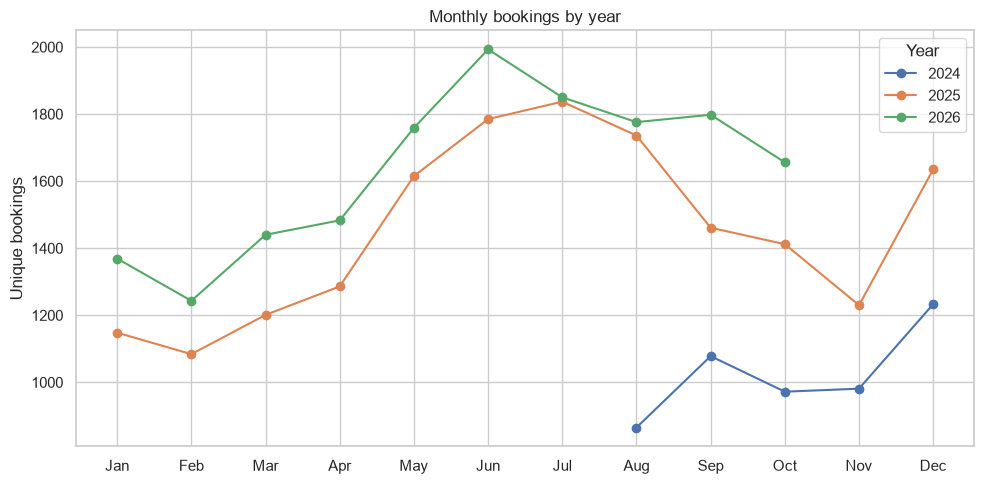

In [89]:
booking_year = (booking_time
           .to_frame("bookings")
           .assign(year=lambda d: d.index.year, month=lambda d: d.index.month)
           .pivot(index="month", columns="year", values="bookings"))

ax = booking_year.plot(figsize=(10, 5), marker="o")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set(title="Monthly bookings by year", xlabel="", ylabel="Unique bookings")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

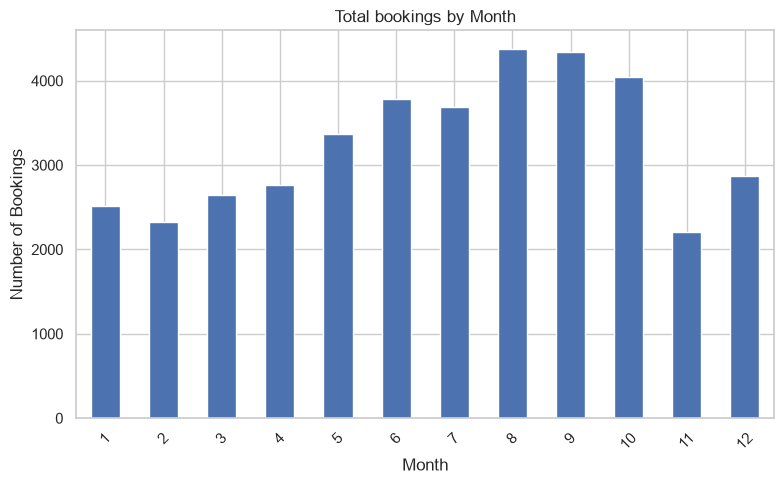

In [ ]:
booking_month= df.groupby("month")["number"].nunique()

booking_month.plot(kind="bar", figsize=(8,5))
plt.title("Total bookings by Month")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

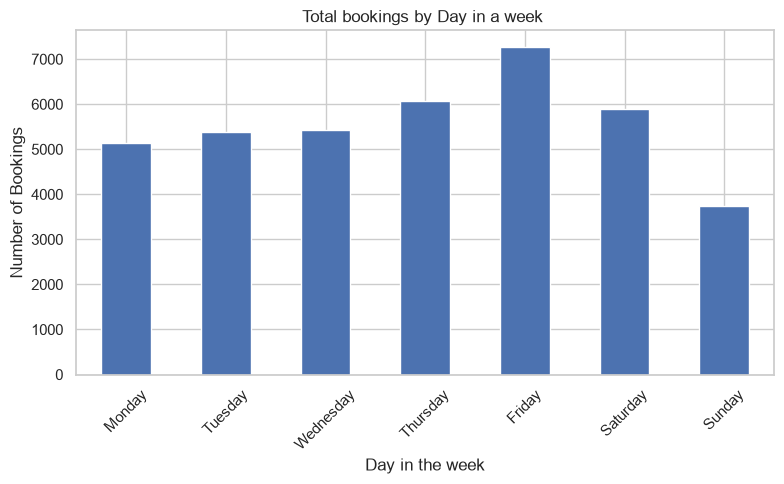

In [43]:
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
booking_day = df.groupby("day_of_week")["number"].nunique()
booking_day = booking_day.reindex(day_order)
booking_day.plot(kind="bar", figsize = (8,5))
plt.title("Total bookings by Day in a week ")
plt.xlabel("Day in the week")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show

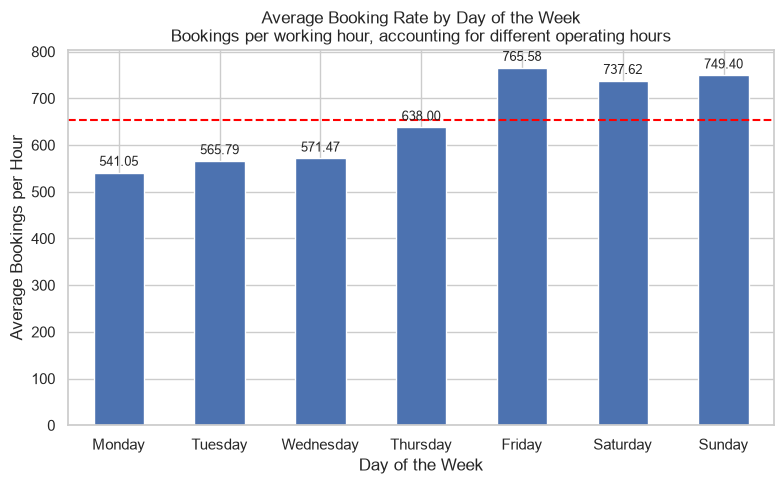

In [62]:
daily_hours = {
    "Monday": 9.5, "Tuesday": 9.5, "Wednesday": 9.5, "Thursday": 9.5, "Friday": 9.5, "Saturday": 8, "Sunday": 5
}
daily_rate = booking_day/booking_day.index.get_level_values("day_of_week").map(daily_hours)
avg_day_rate = daily_rate.groupby("day_of_week").mean()
avg_day_rate = avg_day_rate.reindex(day_order)
ax = avg_day_rate.plot(kind="bar", figsize=(8, 5))

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize = 9)
ax.set_title(
    "Average Booking Rate by Day of the Week\n"
    "Bookings per working hour, accounting for different operating hours",
    fontsize=12
)
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Bookings per Hour")
ax.axhline(
    y=avg_day_rate.mean(),
    color="red",
    linestyle='--',
    linewidth=1.5,
    label='Weekly Average'
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



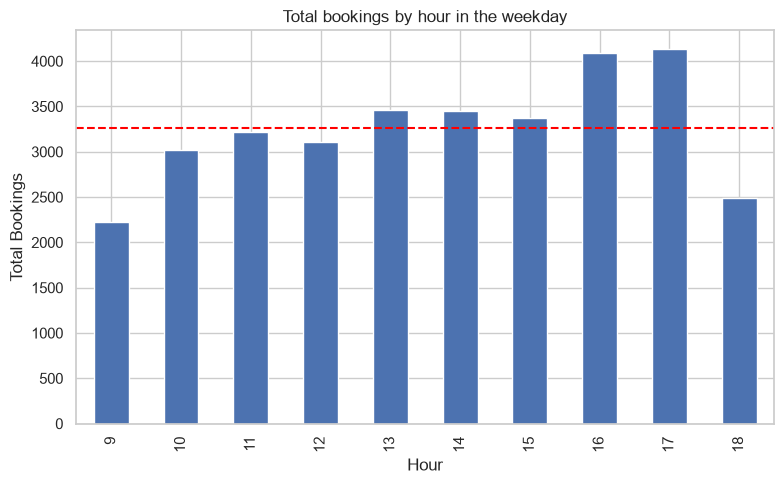

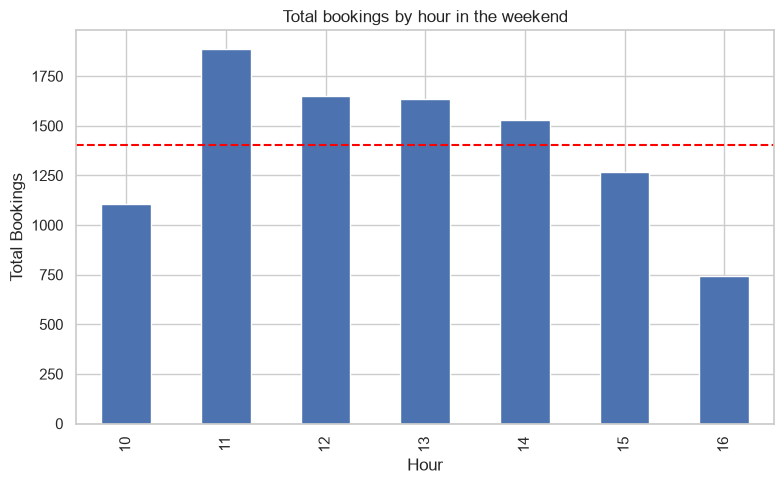

In [93]:
# Bookings per hour
booking_hour_weekday = df[(df["is_weekend"] == False) & (df["hour"]>=9) & (df["hour"]<=18)].groupby("hour")["number"].nunique()
ax = booking_hour_weekday.plot(kind="bar", figsize = (8,5))
ax.set_title("Total bookings by hour in the weekday")
ax.set_xlabel("Hour")
ax.set_ylabel("Total Bookings")
ax.axhline(
    y = booking_hour_weekday.mean(),
    color='red',
    linestyle="--"
)
plt.tight_layout() 
plt.show()

booking_hour_weekend = df[(df["is_weekend"] == True) & (df["hour"]>=10) & (df["hour"]<=16)].groupby("hour")["number"].nunique()
ax = booking_hour_weekend.plot(kind="bar", figsize = (8,5))
ax.set_title("Total bookings by hour in the weekend")
ax.set_xlabel("Hour")
ax.set_ylabel("Total Bookings")
ax.axhline(
    y = booking_hour_weekend.mean(),
    color='red',
    linestyle="--"
)
plt.tight_layout() 
plt.show()


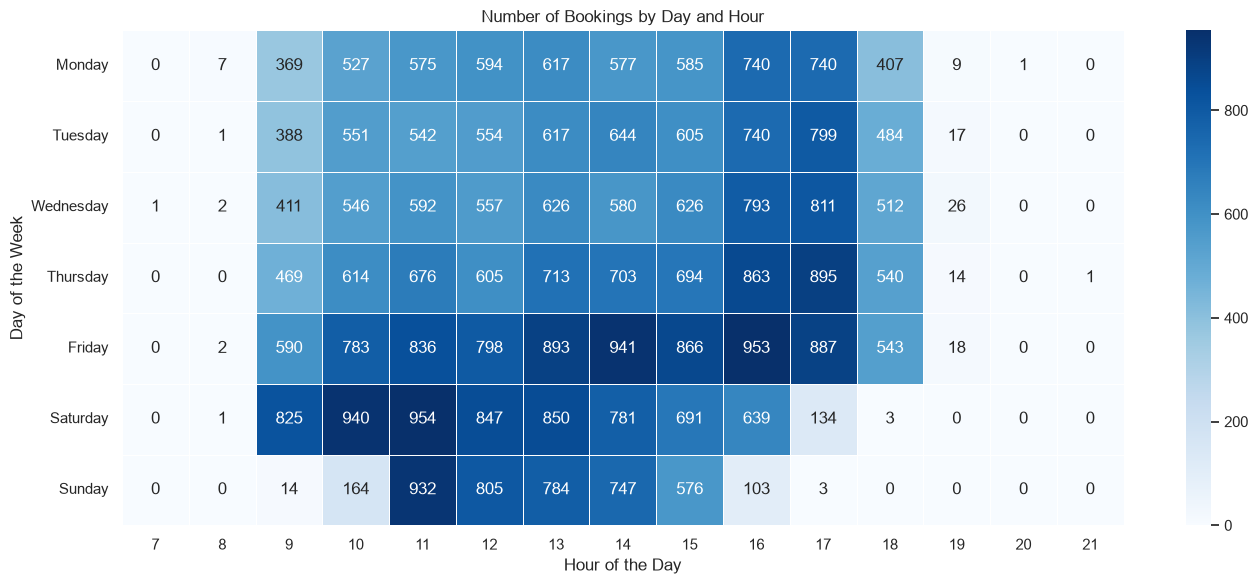

In [97]:
# Bookings through a week with specifc hour
booking_heatmap = df.groupby(["day_of_week","hour"])["number"].nunique().unstack(fill_value=0)
booking_heatmap = booking_heatmap.reindex(day_order)
plt.figure(figsize=(14, 6))

sns.heatmap(
    booking_heatmap,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Number of Bookings by Day and Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Day of the Week")
plt.tight_layout()
plt.show()

**Summary**:
- Overall, it can be seen that Pedi N Nails is a increasing business with increasing number of appointments made throughout the 3-year period. However, it is also a highly seasonal business, with business always has the peak in the summer months (June) before slowing down and picking up again around December before slowing down through spring months until the summer.
- Even though the graph by month may show divergent ideas to the line graph, however, it is totally the nature of dataset, with bookings from 2024 only start from August, and 2026 only covers until October.
- The month Febrauray and November are the two months experieceining the bottom in the number of bookings, which is worth to apply some kinds of promotions to boost the number of customers.
- Friday is the day in the week having the highest number of bookings. However, it is also noteworthy that, the working hours in weekday is longer than the weekend, with 9.5 hours per weekday compared to 8 hours on Saturday and 5 hours on Sunday. Therefore, based on the ratio of average bookings per hour per day in the week, Friday, Saturday, and Sunday are the three having the highest booking rate per working hour, in which, Friday is still the most efficient.
- From the same bookings by day in the week graph, Monday and Tuesday are the slowest day in the week.
- On weekdays, the hour from 4-5 pm is the most busiest time in a day. Morning time from 9 am till noon is slight below average, early afternoon from 1-3pm slight below average, and after 5 is considerable below the average. This should be taken into consideration, as the hour after 5 should have more potential. For weekends, the business has its peak around 11am then slow decreasing till closing.
- Based on this booking patterns according to hour, a conclusion should be drawn is that: This may reflect customers' daily schedules, as demand tends to increase around typical leisure hours after work and during late mornings on weekends.

